In [1]:
# -*- coding: utf-8 -*-
#  Copyright 2021 United Kingdom Research and Innovation
#  Copyright 2021 The University of Manchester
#  Copyright 2021 The Karlsruhe Institute of Technology
#  Copyright 2021 Technical University of Denmark 
#
#  Licensed under the Apache License, Version 2.0 (the "License");
#  you may not use this file except in compliance with the License.
#  You may obtain a copy of the License at
#
#      http://www.apache.org/licenses/LICENSE-2.0
#
#  Unless required by applicable law or agreed to in writing, software
#  distributed under the License is distributed on an "AS IS" BASIS,
#  WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
#  See the License for the specific language governing permissions and
#  limitations under the License.
#
#   Authored by:    Laura Murgatroyd (UKRI-STFC)
#                   Margaret Duff (UKRI-STFC)
#                   Evelina Ametova (KIT)
#                   Jakob S. Jørgensen (DTU)
#                   Gemma Fardell (UKRI-STFC)
#                   Edoardo Pasca (UKRI-STFC)
#                   Hannah Robarts (UKRI-STFC)

# Introduction to FISTA

**The goal** of this notebook is to be able to use the FISTA algorithm.

It works with a 2D slice of an IMAT dataset.

**Learning objectives**

In the end of this session, participants will be able to:
- formulate CT reconstruction as an optimisation problem and solve it iteratively using FISTA
- understand the role of the regularisation parameter, alpha
- run FISTA with two different choices of regulariser
- use a callback to stop the iterations of the algorithm
- compare results to SIRT

In [2]:
# cil imports
from cil.processors import Slicer

from cil.optimisation.algorithms import SIRT
from cil.optimisation.utilities.callbacks import ProgressCallback, EarlyStoppingObjectiveValue

from cil.plugins.astra.operators import ProjectionOperator

from cil.recon import FBP

from cil.utilities.display import show2D, show1D

from cil.optimisation.functions import LeastSquares, L1Norm
from cil.optimisation.algorithms import FISTA
from cil.plugins.ccpi_regularisation.functions import FGP_TV

# External imports
import logging
from skimage.metrics import structural_similarity as ssim
from matplotlib import pyplot as plt

from data_io.alum_cyl_io import read_processed_data
from utils.masks import create_circular_mask
from utils.metrics import calculate_L2Norm_error

import warnings
warnings.filterwarnings("ignore")

/home/laura/miniconda3/envs/cil_demos_26/lib/python3.12/site-packages/cil/processors/CofR_image_sharpness.py:21: UserWarning: A NumPy version >=1.22.4 and <2.3.0 is required for this version of SciPy (detected version 2.4.6)
  import scipy


In [3]:
# Set logging level for CIL processors:
logging.basicConfig(level=logging.WARNING)
cil_log_level = logging.getLogger('cil.processors')
cil_log_level.setLevel(logging.INFO)

In [4]:
# set up default colour map for visualisation
cmap = "inferno"

In [5]:
# set the backend for FBP and the ProjectionOperator
device = 'gpu'

You will need to download the dataset `preprocessed_data.zip` from https://zenodo.org/records/19387166:

    https://zenodo.org/records/19387166/files/preprocessed_data.zip

You will need to update the `processed_data_path` variable in data_io/alum_cyl_file_paths.py to point to this (unzipped) folder.

In [6]:
# read the preprocessed data: full (60 s exposure, 840 angles) and reduced (30 s exposure, 210 angles)
full_data_slice = read_processed_data(exposure_time=60, num_angles=840, vertical=987)
reduced_data_slice = read_processed_data(exposure_time=30, num_angles=210, vertical=987)

In this notebook we will use data from a scan of the aluminium cylinder, comparing a full dataset (840 projections and 60s exposure) with a reduced dataset (210 projections, 30s exposure). The reduced data has 1/8 of the total exposure time of the full data.

We start with data which was already pre-processed in Mantid Imaging, and work with a single 2D slice. For information on the sample, see Angles_vs_Exposure_01_Introduction_to_Aluminium_Cylinder.ipynb.

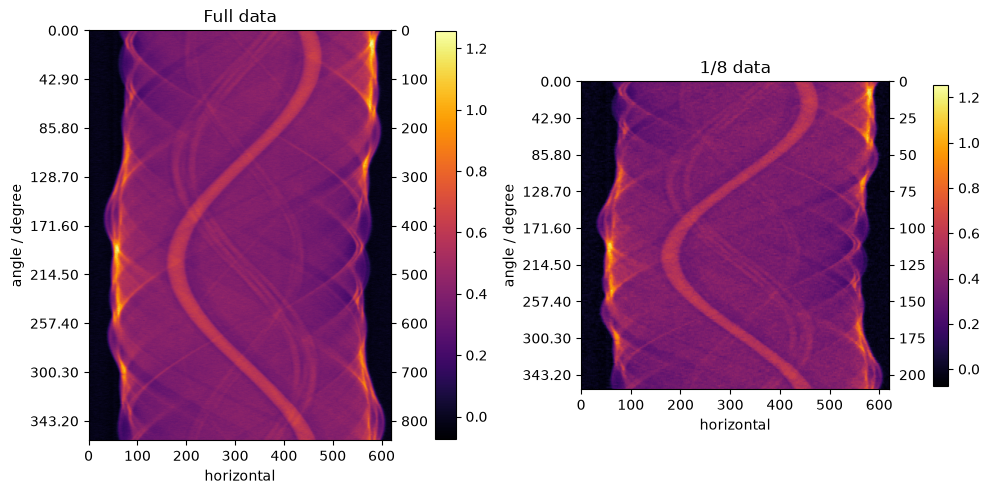

In [7]:
# Visualise data
show2D([full_data_slice, reduced_data_slice], ['Full data', '1/8 data'], cmap=cmap, num_cols=2, size=(10,10), origin='upper-left', fix_range=True)

## CT reconstruction
Tomographic reconstruction consists of resolving the three-dimensional neutron attenuation map of a scanned object from the collection of projection measurements. There are two major classes of reconstruction algorithms: *analytic* and *iterative*.

### FBP

The FBP algorithm is set up with an `AcquisitionData` and an `ImageGeometry`. Calling `run()` returns the reconstructed `ImageData`.

In [8]:
image_geometry = full_data_slice.geometry.get_ImageGeometry()

# reconstruct full and reduced data with FBP
recon_fbp_full = FBP(full_data_slice, image_geometry).run()
recon_fbp_reduced = FBP(reduced_data_slice, image_geometry).run()

FBP recon

Input Data:
	angle: 840
	horizontal: 620

Reconstruction Volume:
	horizontal_y: 620
	horizontal_x: 620

Reconstruction Options:
	Backend: tigre
	Filter: ram-lak
	Filter cut-off frequency: 1.0
	FFT order: 11
	Filter_inplace: False
	Split processing: 0

Reconstructing in 1 chunk(s):



FBP recon

Input Data:
	angle: 210
	horizontal: 620

Reconstruction Volume:
	horizontal_y: 620
	horizontal_x: 620

Reconstruction Options:
	Backend: tigre
	Filter: ram-lak
	Filter cut-off frequency: 1.0
	FFT order: 11
	Filter_inplace: False
	Split processing: 0

Reconstructing in 1 chunk(s):



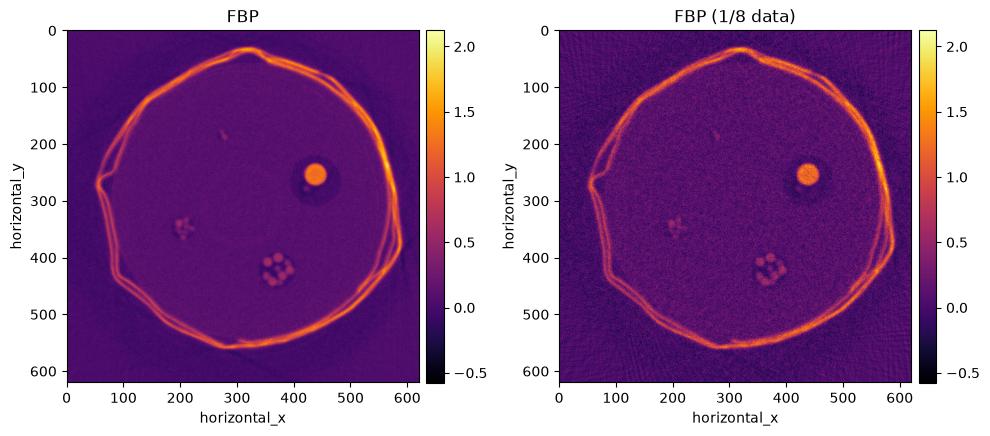

In [9]:
range_min = min(recon_fbp_full.as_array().min(), recon_fbp_reduced.as_array().min())
range_max = max(recon_fbp_full.as_array().max(), recon_fbp_reduced.as_array().max())
show2D([recon_fbp_full, recon_fbp_reduced], ['FBP', 'FBP (1/8 data)'], cmap=cmap, num_cols=2, size=(10,10), origin='upper-left', fix_range=True)

We know that outside the cylinder is just air so we can use a circular mask to remove some noise in the background. Then when we are comparing the reconstructions the results won't be skewed by the background.

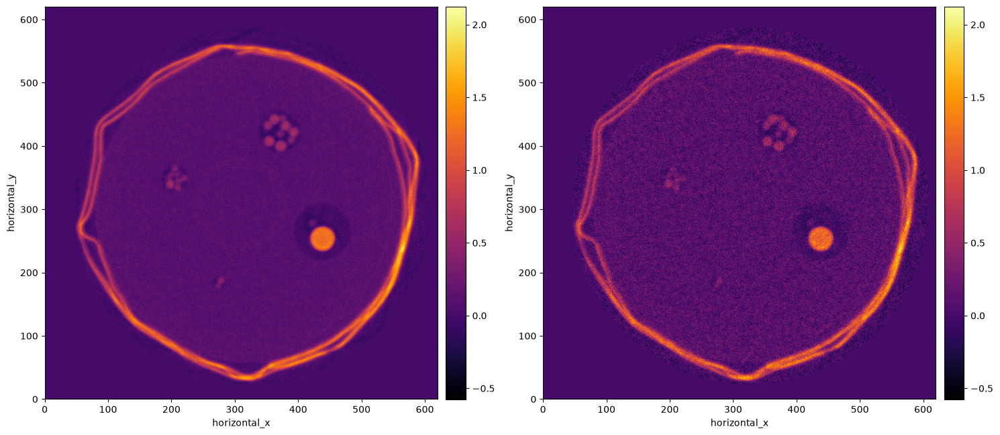

In [10]:
# circular mask applied to reconstructions: centre in pixels (row, col) and radius as a fraction of the half-size
MASK_CENTRE_PX = [305, 327]
MASK_RADIUS = 0.91


masked_fbp_full = create_circular_mask(recon_fbp_full, MASK_CENTRE_PX, radius=MASK_RADIUS, in_place=False)
masked_fbp_reduced = create_circular_mask(recon_fbp_reduced, MASK_CENTRE_PX, radius=MASK_RADIUS, in_place=False)
show2D([masked_fbp_full, masked_fbp_reduced], cmap=cmap, fix_range=True)

### FISTA 
Many useful reconstruction methods involve minimisation of functions that are NOT smooth and in those cases we need dedicated optimisation algorithms for non-smooth problems. In this notebook we consider optimisation problems that can be written in the form
$$\min_u f(u) + g(u)  $$
where $f$ is a smooth function as before, but $g$ may now be non-smooth. $g$ further needs to be "simple", in a certain sense, namely it should have a proximal mapping that is easy to evaluate. Proximal mapping can be thought of a generalisation of the gradient for a non-smooth function.

For this problem class the algorithm FISTA (Fast iterative shrinkage thresholding algorithm) can be employed. It is also known as the accelerated proximal gradient method.

We consider a couple of examples for different functions $g$....


#### FISTA with L1 Norm Penalty

$g$ could simply be used to apply a non-negativity constraint, by using an `IndicatorBox` function in CIL (like we did with SIRT)

Another possibility is sparsity regularisation which we can achieve by choosing $g$ as the L1-norm multiplied by a regularisation parameter $\alpha$ to balance the strength of fitting to the data and enforcing regularisation:
$$g(u) = \alpha\|u\|_1 = \alpha\sum_u |u_i| $$


So we solve


$$\min_u \|Au-b\|_2^2 +  \alpha\sum_u |u_i| $$


We run with a few different values of alpha to assess the impact of the balance between the least-squares data-fidelity term and the regularisation.

To set up FISTA we pass:

F - our Least Squares data-fidelity function

G - our regulariser, multiplied by alpha

In [11]:
alphas = [1e-4, 1e-3, 5e-1]
fista_l1_algos = {alpha: None for alpha in alphas}
# --- build unconstrained fista algorithms ---
for alpha in alphas:
    A = ProjectionOperator(full_data_slice.geometry.get_ImageGeometry(), full_data_slice.geometry)
    b = full_data_slice
    F = LeastSquares(A, b)
    ig = full_data_slice.geometry.get_ImageGeometry()
    G = alpha*L1Norm() 
    initial = ig.allocate(0.0)
    myFISTANN = FISTA(f=F, 
                g=G,  initial=initial,
                update_objective_interval = 10)

    fista_l1_algos[alpha] = myFISTANN


We run FISTA with a callback - EarlyStoppingObjectiveValue.

This stops FISTA iterating when the objective value changes by less than a certain amount per iteration (set by 'threshold). This is an indication that the algorithm has converged.

In [12]:
iteration_nums = 2300

for alpha, fista in fista_l1_algos.items():
    fista.run(iteration_nums, callbacks=[ProgressCallback(), EarlyStoppingObjectiveValue(threshold=1e-5)])

  0%|          | 0/2300 [00:00<?, ?it/s]

  0%|          | 0/2300 [00:00<?, ?it/s]

  0%|          | 0/2300 [00:00<?, ?it/s]

Let's plot the convergence for alpha=1e-3:

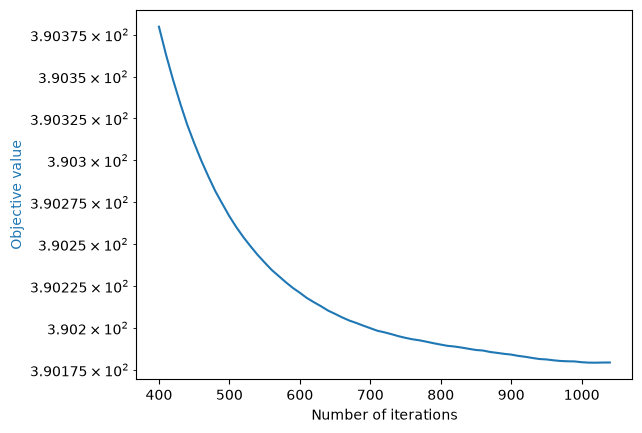

In [13]:

plt.plot(fista_l1_algos[1e-3].iterations[40:], fista_l1_algos[1e-3].loss[40:], color='tab:blue')
# log on y axis:
plt.yscale('log')
plt.xlabel('Number of iterations')
plt.ylabel('Objective value', color='tab:blue')
plt.show()


In [14]:
def title_with_metrics(name, reference, image):
    """Plot title with SSIM and L2NE of `image` compared to `reference` (both 2D ImageData)."""
    ref = reference.as_array()
    ssim_value = ssim(ref, image.as_array(), data_range=ref.max() - ref.min())
    l2_error = calculate_L2Norm_error(reference, image)
    return '{}, SSIM: {:.3f}, L2NE: {:.4f}'.format(name, ssim_value, l2_error)

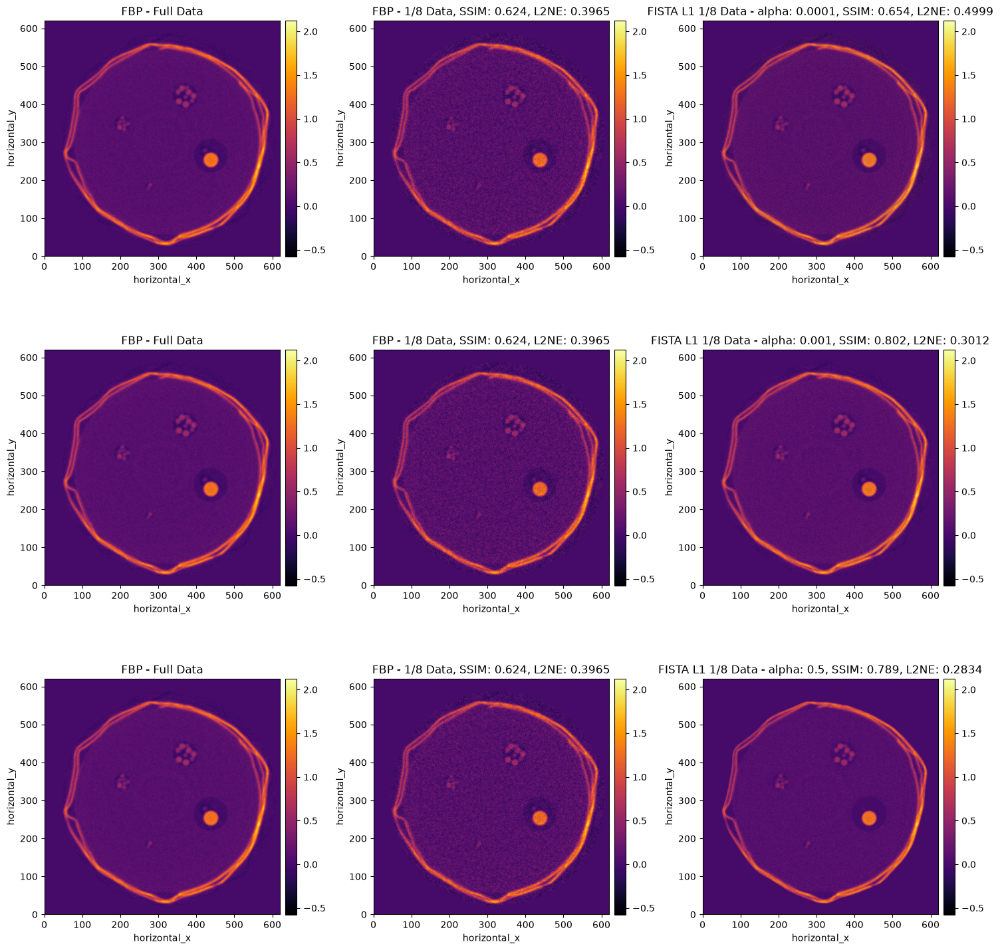

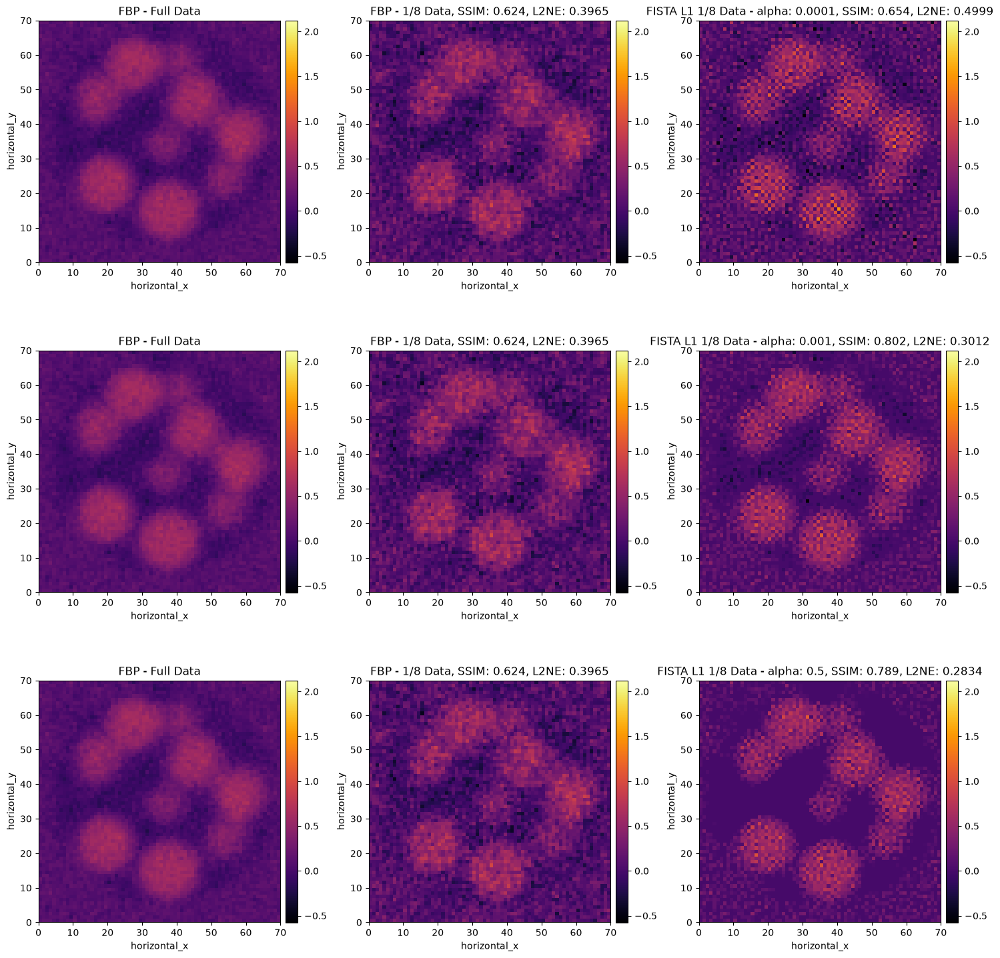

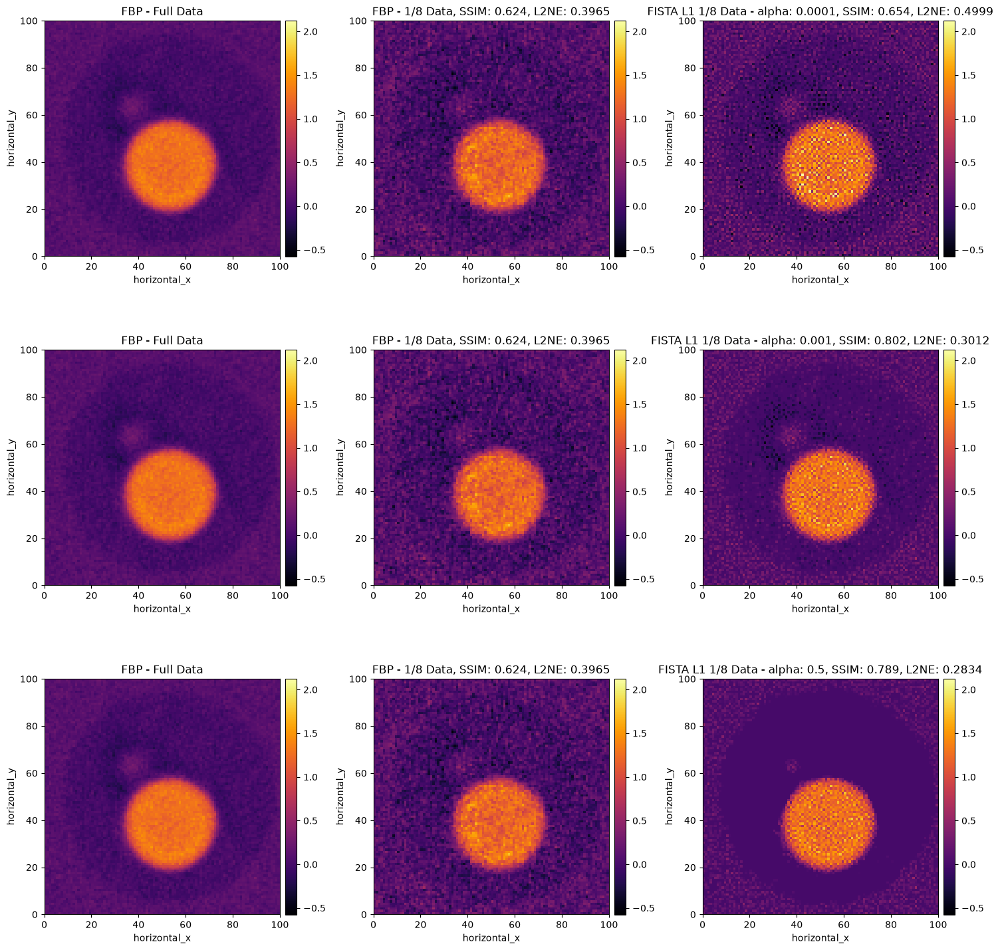

In [15]:
slicers = [None, Slicer(roi={'horizontal_x': (335, 405), 'horizontal_y': (385, 455)}), Slicer(roi={'horizontal_x': (385, 485), 'horizontal_y': (215, 315)})]
for slicer in slicers:
    fista_titles = [f"FISTA L1 1/8 Data - alpha: {alpha}" for alpha in alphas]
    fista_results = [fista_l1_algos[alpha].solution for alpha in alphas]
    fbp_titles = [f"FBP - 1/8 Data" for alpha in alphas]
    fbp_results = [masked_fbp_reduced]*len(alphas)

    images = []
    titles = []
    masked_fbp_full = masked_fbp_full
    for alpha, fista_img, fista_title, masked_fbp_reduced, fbp_title in zip(alphas, fista_results, fista_titles, fbp_results, fbp_titles):
        fista_img = create_circular_mask(fista_img, MASK_CENTRE_PX, radius=MASK_RADIUS, in_place=False)
        data_list = [masked_fbp_full, masked_fbp_reduced, fista_img]
        if slicer is not None:
            data_list = [slicer(img) for img in data_list]
        images.extend(data_list)
        titles.extend([f"FBP - Full Data",
                    title_with_metrics(fbp_title, masked_fbp_full, masked_fbp_reduced),
                    title_with_metrics(fista_title, masked_fbp_full, fista_img)])


    show2D(images, title=titles, cmap=cmap, fix_range=(range_min, range_max), num_cols=3)

We see the solutions are still very noisy. Having an alpha too low makes the image especially noisy. With a higher alpha, we lose some features with some spheres reduced in size

#### FISTA with TV
Sometimes a better option is to enforce sparsity of the image gradient. This is known as Total Variation (TV) regularisation and tends to enforce piecewise constant areas separated by sharp edges. So TV may have an advantage if the image to be reconstructed is known to consist of relatively homogeneous areas separated by sharp edges. 

The Total Variation is defined as $$\mathrm{TV}(u) = \|\nabla u \|_{2,1} = \sum \sqrt{ (\partial_{y}u)^{2} + (\partial_{x}u)^{2} }$$

So we solve: $$\min_u \|Au-b\|_2^2 + \alpha\mathrm{TV}(u) $$



In CIL, TV is available as the TotalVariation function and from the CCPi regularisation toolkit as FGP_TV which can be run on the GPU. We can set up and solve the TV-regularised problem by passing alpha * TV as G:

In [16]:
alphas = [2e-4, 1e-3,5e-3, 1e-1]
fista_tv_algos = {alpha: None for alpha in alphas}
# --- build unconstrained fista algorithms ---
for alpha in alphas:
    A = ProjectionOperator(full_data_slice.geometry.get_ImageGeometry(), full_data_slice.geometry)
    b = full_data_slice
    F = LeastSquares(A, b)
    ig = full_data_slice.geometry.get_ImageGeometry()
    GTV = alpha*FGP_TV(device='gpu') 
    initial = ig.allocate(0.0)
    myFISTANN = FISTA(f=F, 
                g=GTV,  initial=initial,
                update_objective_interval = 10)

    fista_tv_algos[alpha] = myFISTANN

We run each algorithm for a maximum of 2300 iterations but use a stopping rule based on change in objective value to determine whether convergence has been reached. If the objective value changes by less than our threshold of 1e-5 then the algorithm will stop iterating:

In [17]:
iteration_nums = 2300

for alpha, fista in fista_tv_algos.items():
    fista.run(iteration_nums, callbacks=[ProgressCallback(), EarlyStoppingObjectiveValue(threshold=1e-5)])

  0%|          | 0/2300 [00:00<?, ?it/s]

  0%|          | 0/2300 [00:00<?, ?it/s]

  0%|          | 0/2300 [00:00<?, ?it/s]

  0%|          | 0/2300 [00:00<?, ?it/s]

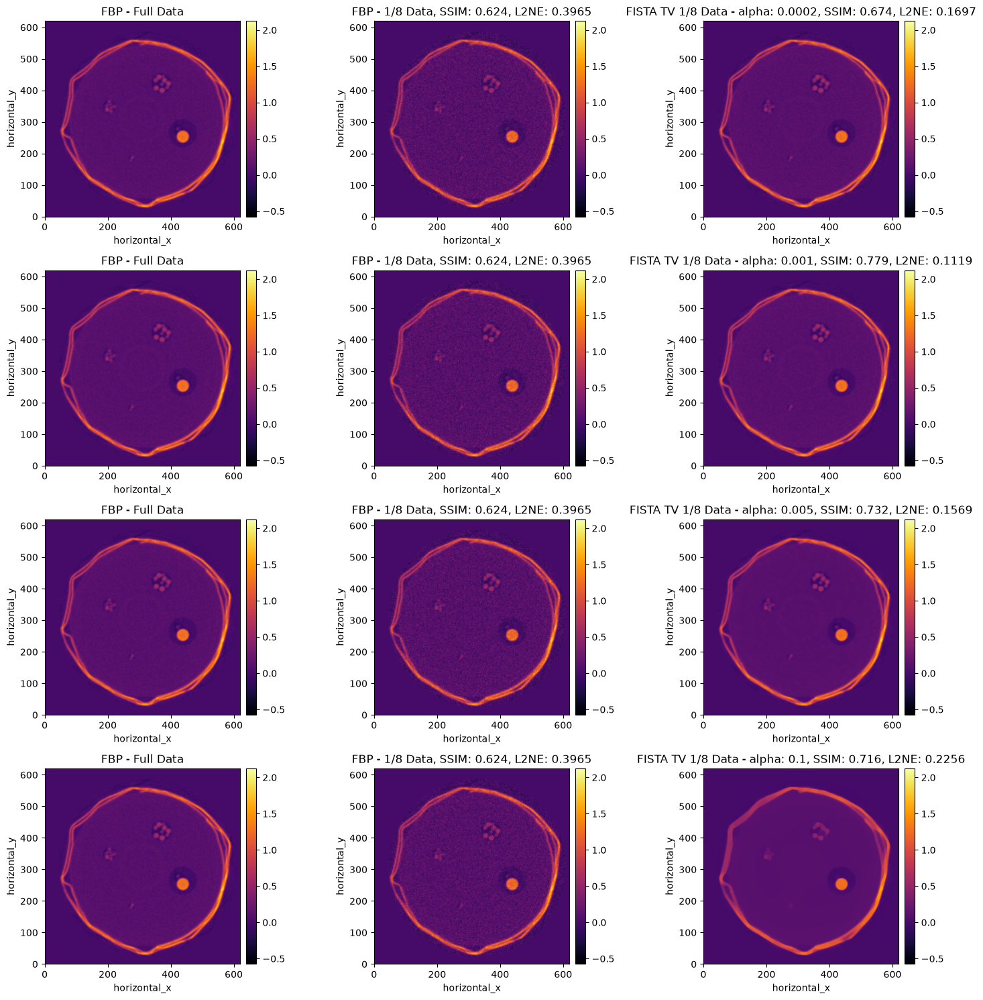

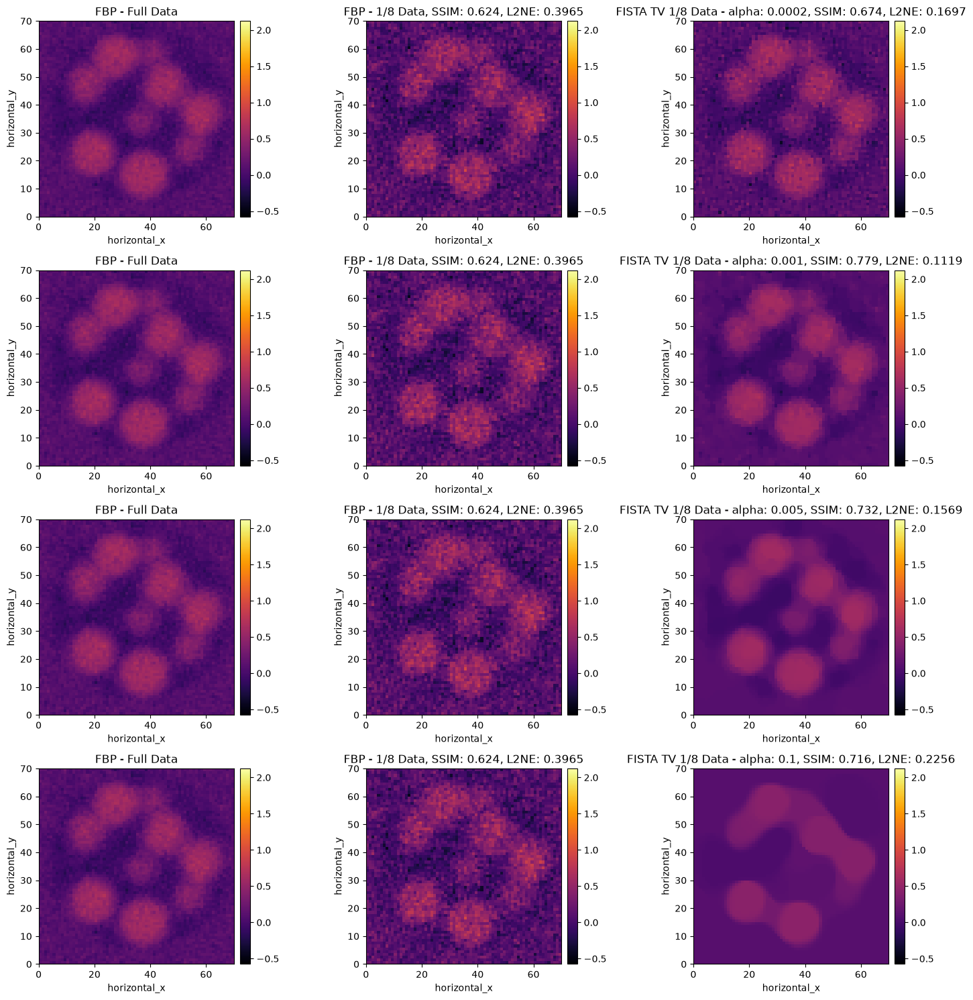

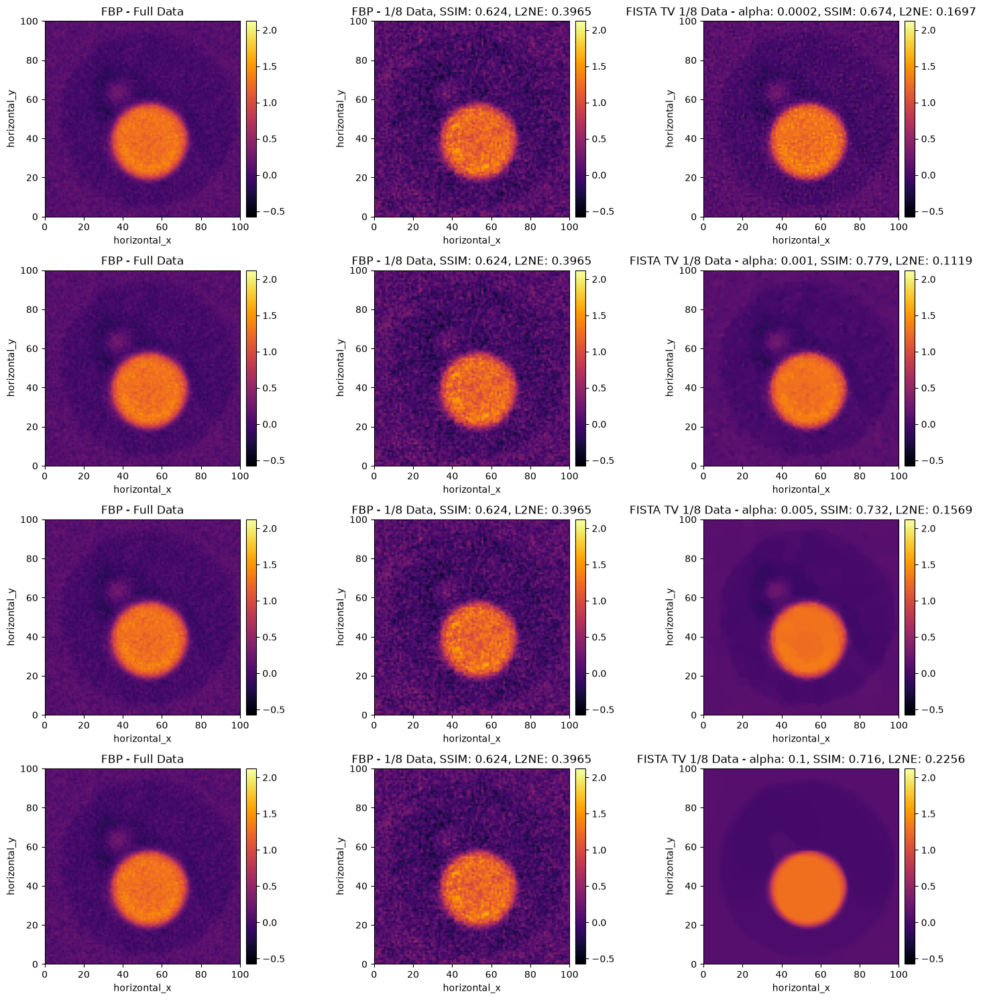

In [18]:
slicers = [None, Slicer(roi={'horizontal_x': (335, 405), 'horizontal_y': (385, 455)}), Slicer(roi={'horizontal_x': (385, 485), 'horizontal_y': (215, 315)})]
for slicer in slicers:
    fista_titles = [f"FISTA TV 1/8 Data - alpha: {alpha}" for alpha in alphas]
    fista_results = [fista_tv_algos[alpha].solution for alpha in alphas]
    fbp_titles = [f"FBP - 1/8 Data" for alpha in alphas]
    fbp_results = [masked_fbp_reduced]*len(alphas)

    images = []
    titles = []
    masked_fbp_full = masked_fbp_full
    for alpha, fista_img, fista_title, masked_fbp_reduced, fbp_title in zip(alphas, fista_results, fista_titles, fbp_results, fbp_titles):
        data_list = [masked_fbp_full, masked_fbp_reduced, create_circular_mask(fista_img, MASK_CENTRE_PX, radius=MASK_RADIUS, in_place=False)]
        if slicer is not None:
            data_list = [slicer(img) for img in data_list]
        images.extend(data_list)
        titles.extend([f"FBP - Full Data",
                    title_with_metrics(fbp_title, masked_fbp_full, masked_fbp_reduced),
                    title_with_metrics(fista_title, masked_fbp_full, fista_img)])


    show2D(images, title=titles, cmap=cmap, fix_range=(range_min, range_max), num_cols=3)

With alpha too low, the solution is noisy.
With alpha too high, our features are blurring together - we have too much smoothing.
Let's pick alpha=0.001

Compare with SIRT from before:

In [19]:
initial = image_geometry.allocate(0)

A = ProjectionOperator(image_geometry, reduced_data_slice.geometry, device=device)

sirt = SIRT(initial=initial, operator=A, data=reduced_data_slice)
sirt.update_objective_interval = 10

sirt.run(200)


  0%|          | 0/200 [00:00<?, ?it/s]

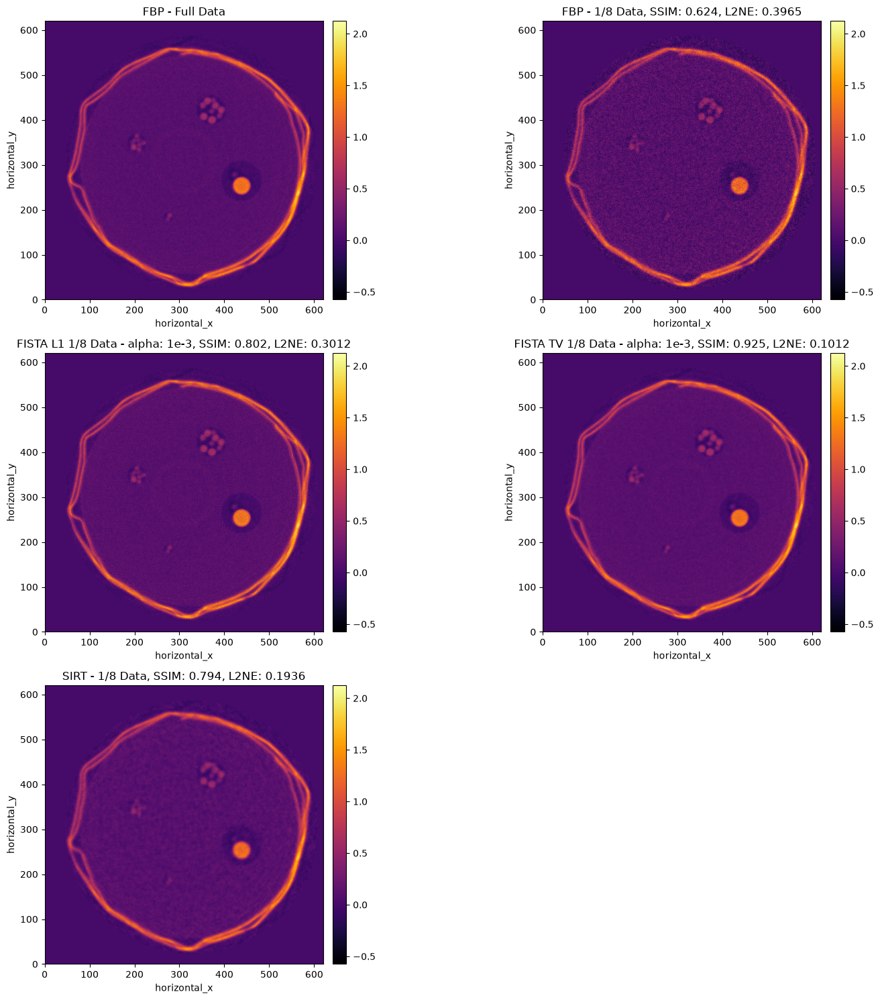

In [25]:
fista_img = create_circular_mask(fista_tv_algos[1e-3].solution, MASK_CENTRE_PX, radius=MASK_RADIUS, in_place=False)
fista_l1_img = create_circular_mask(fista_l1_algos[1e-3].solution, MASK_CENTRE_PX, radius=MASK_RADIUS, in_place=False)
sirt_img = create_circular_mask(sirt.solution, MASK_CENTRE_PX, radius=MASK_RADIUS, in_place=False)
fbp_title = "FBP - 1/8 Data"
fista_title = "FISTA TV 1/8 Data - alpha: 1e-3"
fista_l1_title = "FISTA L1 1/8 Data - alpha: 1e-3"
sirt_title = "SIRT - 1/8 Data"

# Full image
images = [masked_fbp_full, masked_fbp_reduced, fista_l1_img, fista_img, sirt_img]
titles = ["FBP - Full Data",
          title_with_metrics(fbp_title, masked_fbp_full, masked_fbp_reduced),
          title_with_metrics(fista_l1_title, masked_fbp_full, fista_l1_img),
          title_with_metrics(fista_title, masked_fbp_full, fista_img),
          title_with_metrics(sirt_title, masked_fbp_full, sirt_img)]

vmin = min(img.min() for img in images)
vmax = max(img.max() for img in images)

show2D(images, title=titles, cmap=cmap, fix_range=(range_min, range_max), num_cols=2)


Let's have a look at some ROIs in the sample:

This first ROI shows a slice of a cylindrical hole containing a mixture of ZrO2 spheres (0.5mm diameter) and trisopheres (1mm diameter)

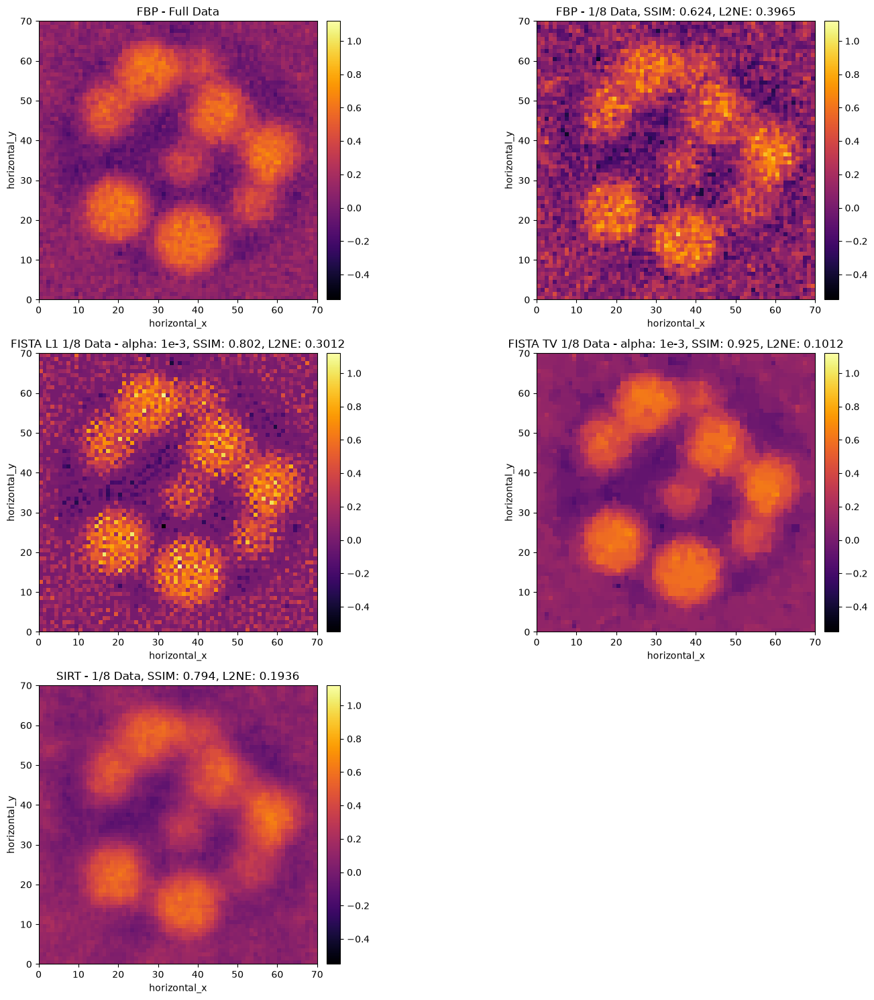

In [21]:
# Zoomed: multiple beads ROI
slicer = Slicer(roi={'horizontal_x': (335, 405), 'horizontal_y': (385, 455)})
images = [slicer(img) for img in [masked_fbp_full, masked_fbp_reduced, fista_l1_img, fista_img, sirt_img]]
titles = ["FBP - Full Data",
          title_with_metrics(fbp_title, masked_fbp_full, masked_fbp_reduced),
          title_with_metrics(fista_l1_title, masked_fbp_full, fista_l1_img),
          title_with_metrics(fista_title, masked_fbp_full, fista_img),
          title_with_metrics(sirt_title, masked_fbp_full, sirt_img)]

vmin = min(img.min() for img in images)
vmax = max(img.max() for img in images)

show2D(images, title=titles, cmap=cmap, fix_range=True, num_cols=2)


In this second ROI we see a slice of a cylindrical hole which contains steel spheres (2mm diameter) in Aluminium foil.

We can see a large cut through of a sphere, but also the top of a second sphere is visible in the full FBP reconstruction, to the top left of the large sphere.

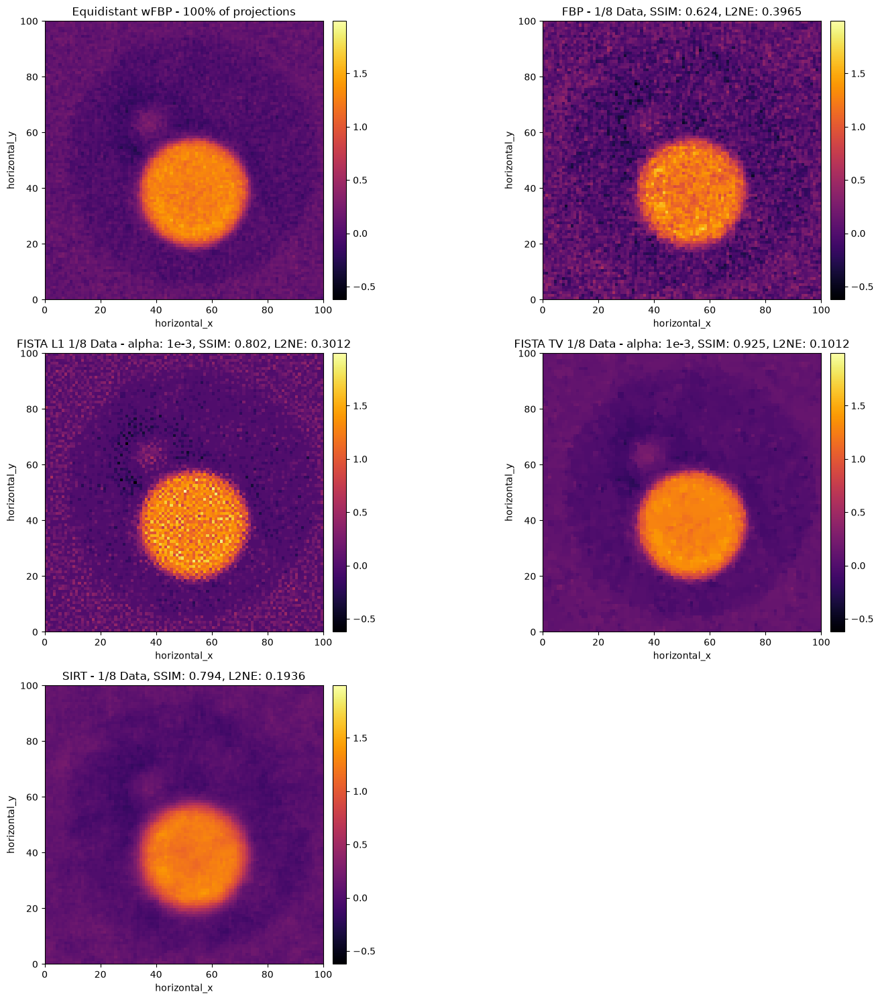

In [22]:
# Zoomed: large and small rods ROI
slicer = Slicer(roi={'horizontal_x': (385, 485), 'horizontal_y': (215, 315)})
images = [slicer(img) for img in [masked_fbp_full, masked_fbp_reduced, fista_l1_img, fista_img, sirt_img]]
titles = ["Equidistant wFBP - 100% of projections",
          title_with_metrics(fbp_title, masked_fbp_full, masked_fbp_reduced),
          title_with_metrics(fista_l1_title, masked_fbp_full, fista_l1_img),
          title_with_metrics(fista_title, masked_fbp_full, fista_img),
          title_with_metrics(sirt_title, masked_fbp_full, sirt_img)]

vmin = min(img.min() for img in images)
vmax = max(img.max() for img in images)

show2D(images, title=titles, cmap=cmap, fix_range=True, num_cols=2)


Across all of the ROIs we see the highest SSIM with FISTA-TV and the lowest L2 Norm Error with FISTA-TV

Next we look at line profiles. We don't plot the line profiles for FISTA-L1 as its so noisy...

This shows a line profile through the largest cut of a sphere:

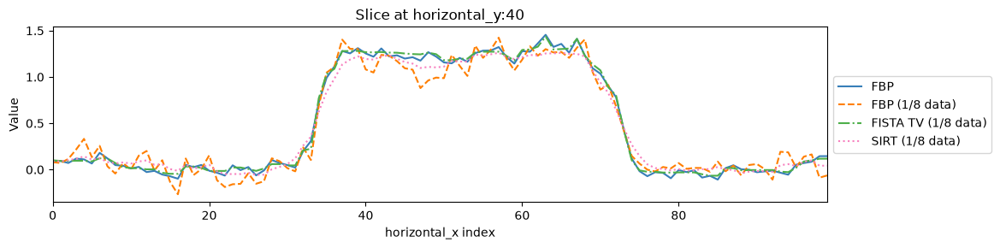

In [23]:
images.pop(2)
show1D(images, slice_list=[('horizontal_y', 40)], dataset_labels=['FBP', 'FBP (1/8 data)', 'FISTA TV (1/8 data)', 'SIRT (1/8 data)'], size=(12,3))

We see above that with SIRT, the boundary of the sphere has been blurred, especially seen on the left of the line profile. This doesn't happen with FISTA TV.

Next, a line profile through the smallest cut of a sphere:

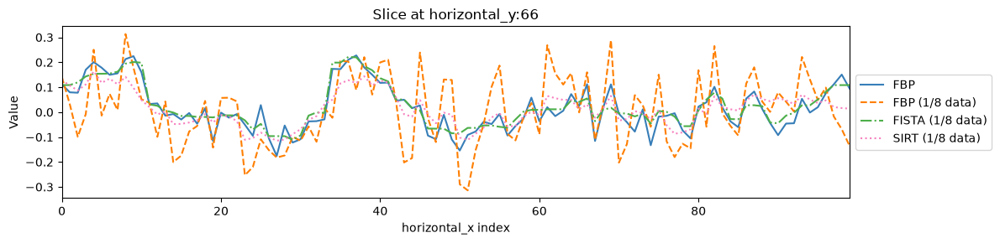

In [24]:
show1D(images, slice_list=[('horizontal_y', 66)], dataset_labels=['FBP', 'FBP (1/8 data)', 'FISTA (1/8 data)', 'SIRT (1/8 data)'], size=(12,3))

We see its better defined with FISTA-TV than SIRT.

**Exercise:** Try changing the list of alpha values we use with FISTA-TV and see what happens. Can you find a more preferable alpha?